# Detection multi-figures avec les fonctions sources

Ce notebook utilise directement les fonctions de `src` : generation du dataset sur disque, chargement par `ShapeDataset`, encodage par `code()`, entrainement, evaluation et prediction.

In [8]:
import sys
import random
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageDraw
from torch.utils.data import DataLoader

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.dataset_generator_3 import generate
from src.detector import (
    ANCHORS,
    NMS_IOU_THRESHOLD,
    RATIO_MAX,
    SCORE_THRESHOLD,
    STRIDE,
    Detector,
    ShapeDataset,
    decode,
    predict,
)
from src.train2 import create_datasets, evaluate_model, train_model
from src.visualize import show_detections, show_feature_maps, show_images
MODEL_SIZE = 64
TRAIN_SAMPLES = 2000
VAL_SAMPLES = 400
BATCH_SIZE = 64
EPOCHS = 50
LR = 3e-3
BASELINE_ANCHORS = ((1.0, 1.0),)

assert MODEL_SIZE % STRIDE == 0
print(f"Projet : {PROJECT_ROOT}")
print(f"Grille du modele : {MODEL_SIZE // STRIDE}x{MODEL_SIZE // STRIDE}")

Projet : c:\Users\islem\Downloads\mini_projet_reseau_neurone\MiniProjet-r-seauDeNeurones\sujet_tensorboard
Grille du modele : 8x8


## 1. Generation du dataset sur disque

Contrairement a l'ancien notebook, la generation passe par `generate()`. Les images et leurs annotations sont donc produits exactement comme le prevoit `dataset_generator_3.py`.

In [9]:
DATA_ROOT = Path(tempfile.gettempdir()) / "mini_projet_reseau_neurone_demo2"
generate(
    output=DATA_ROOT,
    size=MODEL_SIZE,
    train=TRAIN_SAMPLES,
    val=VAL_SAMPLES,
    shape="circle",
    min_objects=2,
    max_objects=4,
    seed=7,
)
print("Dossier train :", DATA_ROOT / "train")
print("Dossier val   :", DATA_ROOT / "val")

2400 images générées dans C:\Users\islem\AppData\Local\Temp\mini_projet_reseau_neurone_demo2
Figures : circle, de 2 à 4 par image
Dossier train : C:\Users\islem\AppData\Local\Temp\mini_projet_reseau_neurone_demo2\train
Dossier val   : C:\Users\islem\AppData\Local\Temp\mini_projet_reseau_neurone_demo2\val


## 2. Verification du format PNG/TXT

Chaque ligne du fichier TXT correspond a une figure et contient `cx cy w h` en pixels. On lit ici les fichiers crees par `generate()` pour suivre les dimensions des boites avant leur encodage.

In [10]:
sample_paths = sorted((DATA_ROOT / "train").glob("*.png"))[:10]
for image_path in sample_paths:
    label_path = image_path.with_suffix(".txt")
    lines = label_path.read_text(encoding="utf-8").strip().splitlines()
    print(f"{image_path.name}: {len(lines)} objet(s)")
    for number, line in enumerate(lines, start=1):
        cx, cy, width, height = map(float, line.split())
        print(f"  objet {number}: centre=({cx:.1f}, {cy:.1f}), taille=({width:.1f}, {height:.1f})")

00000.png: 2 objet(s)
  objet 1: centre=(49.0, 11.0), taille=(16.0, 16.0)
  objet 2: centre=(51.5, 11.5), taille=(11.0, 11.0)
00001.png: 3 objet(s)
  objet 1: centre=(12.5, 41.5), taille=(19.0, 19.0)
  objet 2: centre=(8.5, 38.5), taille=(13.0, 13.0)
  objet 3: centre=(10.0, 34.0), taille=(16.0, 16.0)
00002.png: 2 objet(s)
  objet 1: centre=(36.0, 12.0), taille=(18.0, 18.0)
  objet 2: centre=(31.5, 9.5), taille=(19.0, 19.0)
00003.png: 4 objet(s)
  objet 1: centre=(12.5, 45.5), taille=(19.0, 19.0)
  objet 2: centre=(12.5, 39.5), taille=(19.0, 19.0)
  objet 3: centre=(8.5, 43.5), taille=(13.0, 13.0)
  objet 4: centre=(8.0, 46.0), taille=(12.0, 12.0)
00004.png: 4 objet(s)
  objet 1: centre=(41.5, 24.5), taille=(11.0, 11.0)
  objet 2: centre=(45.0, 21.0), taille=(18.0, 18.0)
  objet 3: centre=(45.5, 21.5), taille=(11.0, 11.0)
  objet 4: centre=(42.0, 20.0), taille=(20.0, 20.0)
00005.png: 4 objet(s)
  objet 1: centre=(14.5, 46.5), taille=(21.0, 21.0)
  objet 2: centre=(15.0, 45.0), taille=(

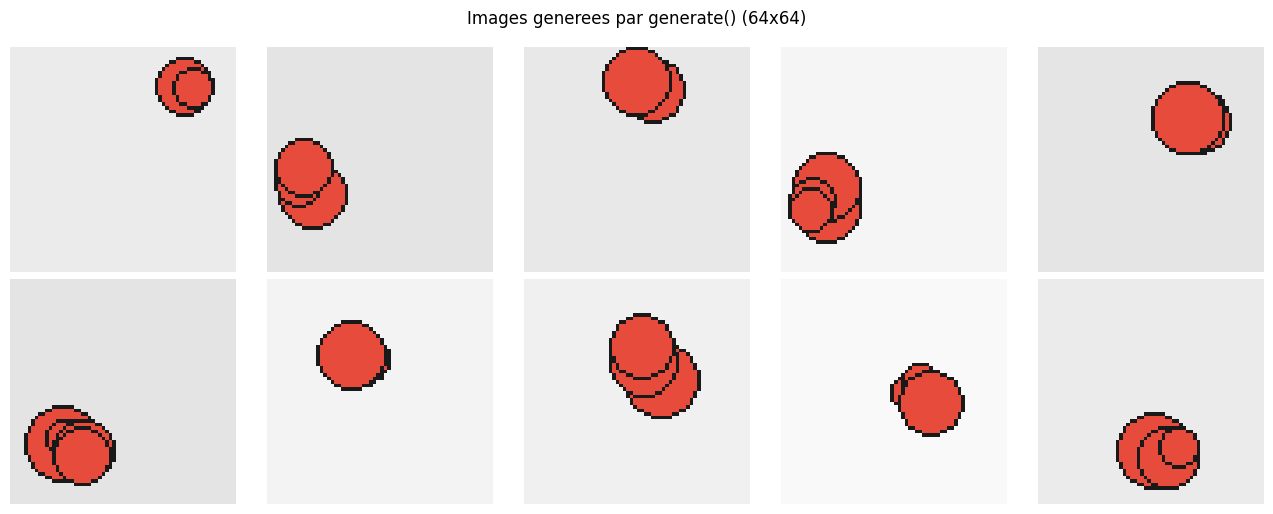

In [11]:
pil_images = [Image.open(path).convert("RGB") for path in sample_paths]
show_images(pil_images, f"Images generees par generate() ({MODEL_SIZE}x{MODEL_SIZE})")

## 3. Chargement par `ShapeDataset`

`ShapeDataset` relit les PNG et les TXT. Il transforme l'image en tenseur `(3, 64, 64)` et appelle ensuite `code()` pour fabriquer la cible `(K*5, 8, 8)`. Le notebook ne recopie donc pas la logique d'encodage.

In [12]:
train_dataset, val_dataset = create_datasets(DATA_ROOT, size=MODEL_SIZE, anchors=ANCHORS)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
image_tensor, target_tensor = train_dataset[0]
print("Nombre train :", len(train_dataset))
print("Nombre val   :", len(val_dataset))
print("Image        :", tuple(image_tensor.shape))
print("Cible        :", tuple(target_tensor.shape))
print("Ancres       :", len(ANCHORS))
print("Canaux cible :", len(ANCHORS), "x 5")

Nombre train : 2000
Nombre val   : 400
Image        : (3, 64, 64)
Cible        : (15, 8, 8)
Ancres       : 3
Canaux cible : 3 x 5


Cellules positives par ancre : [1, 0, 1]


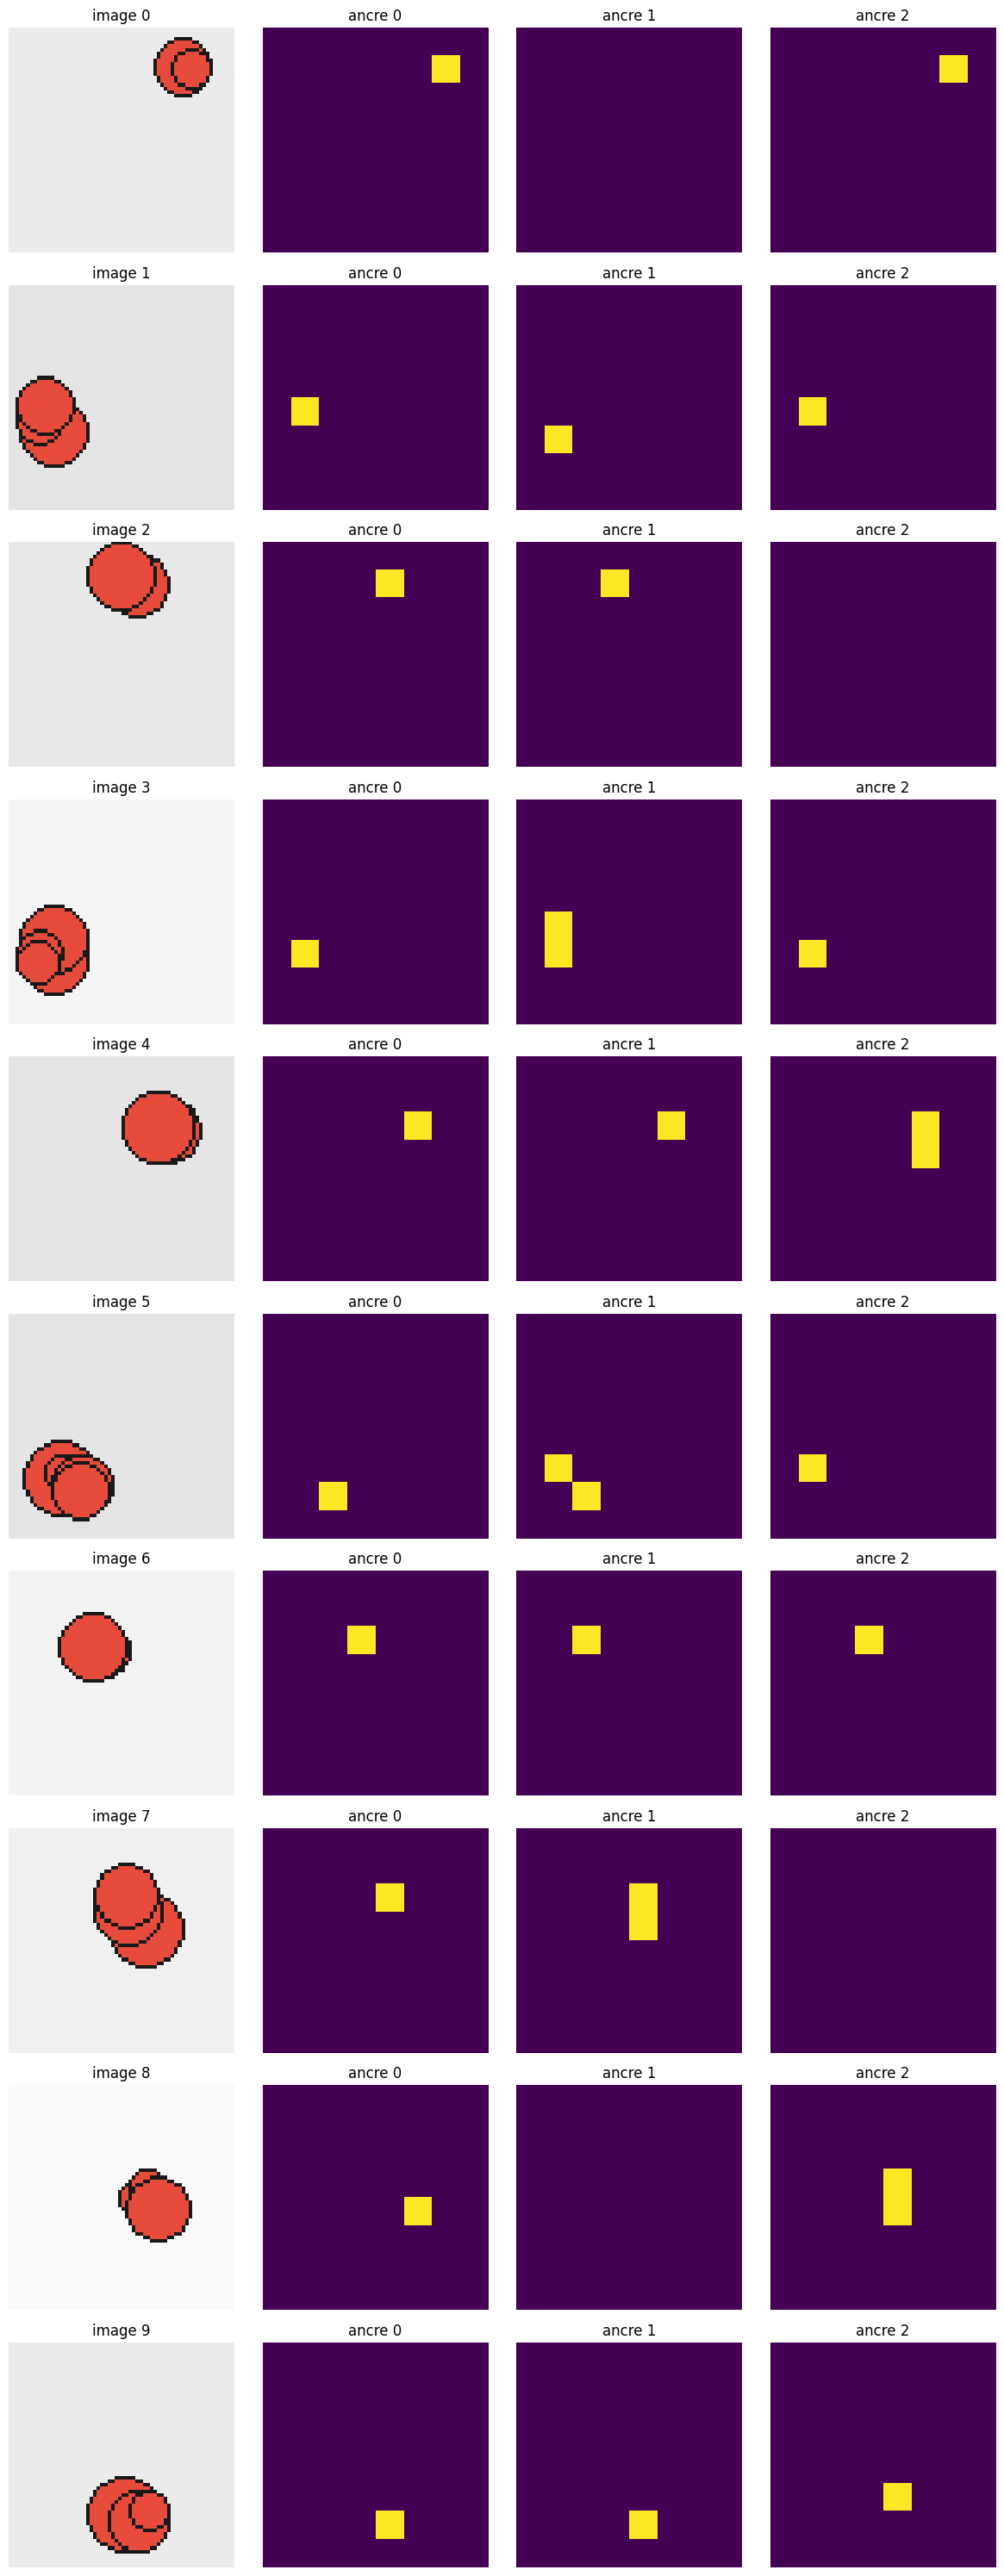

In [25]:
target_view = target_tensor.reshape(len(ANCHORS), 5, MODEL_SIZE // STRIDE, MODEL_SIZE // STRIDE)
objectness = target_view[:, 0]
print("Cellules positives par ancre :", [int((objectness[k] > 0.5).sum()) for k in range(len(ANCHORS))])
target_images = torch.stack([train_dataset[i][0] for i in range(min(10, len(train_dataset)))])
target_maps = torch.stack([
    train_dataset[i][1].reshape(len(ANCHORS), 5, MODEL_SIZE // STRIDE, MODEL_SIZE // STRIDE)[:, 0]
    for i in range(min(10, len(train_dataset)))
])
fig, axes = plt.subplots(len(target_images), len(ANCHORS) + 1, figsize=(3 * (len(ANCHORS) + 1), 3 * len(target_images)), squeeze=False)
for image_index, row_axes in enumerate(axes):
    row_axes[0].imshow(target_images[image_index].permute(1, 2, 0))
    row_axes[0].set_title(f"image {image_index}")
    for anchor_index, axis in enumerate(row_axes[1:]):
        axis.imshow(target_maps[image_index, anchor_index], vmin=0, vmax=1, cmap="viridis")
        axis.set_title(f"ancre {anchor_index}")
    for axis in row_axes:
        axis.axis("off")
fig.tight_layout()
plt.show()

## 4. Entrainement des deux configurations

`train_model()` compare les sorties brutes du modele aux cibles produites par `code()`, uniquement pour calculer la loss. `evaluate_model()` relit les boites originales des fichiers TXT et compare ces boites aux sorties finales de `predict()`, donc apres `decode()`, le seuil de confiance et le NMS.

In [14]:
def fit(name, anchors):
    torch.manual_seed(0)
    train_data, val_data = create_datasets(DATA_ROOT, size=MODEL_SIZE, anchors=anchors)
    train_data_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
    val_data_loader = DataLoader(val_data, batch_size=BATCH_SIZE)
    model = Detector(anchors)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"loss": [], "mean_iou": [], "recall": [], "precision": []}
    for epoch in range(1, EPOCHS + 1):
        mean_loss = train_model(model, train_data_loader, optimizer)
        metrics = evaluate_model(model, val_data, MODEL_SIZE, batch_size=BATCH_SIZE)
        history["loss"].append(mean_loss)
        for key in ("mean_iou", "recall", "precision"):
            history[key].append(metrics[key])
        print(
            f"[{name}] epoch {epoch:2d} loss {mean_loss:.4f} "
            f"IoU {metrics['mean_iou']:.3f} "
            f"rappel {metrics['recall']:.0%} "
            f"precision {metrics['precision']:.0%}"
        )
    model.eval()
    return model, history
print("--- Modele de base : 1 ancre ---")
model_base, history_base = fit("K=1", BASELINE_ANCHORS)
print("--- Modele multi-objets : 3 ancres ---")
model_k3, history_k3 = fit("K=3", ANCHORS)

--- Modele de base : 1 ancre ---
[K=1] epoch  1 loss 0.9432 IoU 0.162 rappel 10% precision 22%
[K=1] epoch  2 loss 0.4918 IoU 0.391 rappel 49% precision 71%
[K=1] epoch  3 loss 0.3361 IoU 0.377 rappel 46% precision 71%
[K=1] epoch  4 loss 0.2691 IoU 0.367 rappel 48% precision 81%
[K=1] epoch  5 loss 0.2419 IoU 0.369 rappel 45% precision 74%
[K=1] epoch  6 loss 0.2279 IoU 0.348 rappel 44% precision 81%
[K=1] epoch  7 loss 0.2171 IoU 0.391 rappel 48% precision 74%
[K=1] epoch  8 loss 0.2116 IoU 0.364 rappel 46% precision 81%
[K=1] epoch  9 loss 0.2079 IoU 0.385 rappel 48% precision 73%
[K=1] epoch 10 loss 0.2031 IoU 0.396 rappel 49% precision 75%
[K=1] epoch 11 loss 0.1986 IoU 0.384 rappel 47% precision 73%
[K=1] epoch 12 loss 0.1955 IoU 0.383 rappel 47% precision 69%
[K=1] epoch 13 loss 0.1943 IoU 0.393 rappel 48% precision 77%
[K=1] epoch 14 loss 0.1892 IoU 0.347 rappel 44% precision 84%
[K=1] epoch 15 loss 0.1868 IoU 0.368 rappel 45% precision 71%
[K=1] epoch 16 loss 0.1834 IoU 0.352 

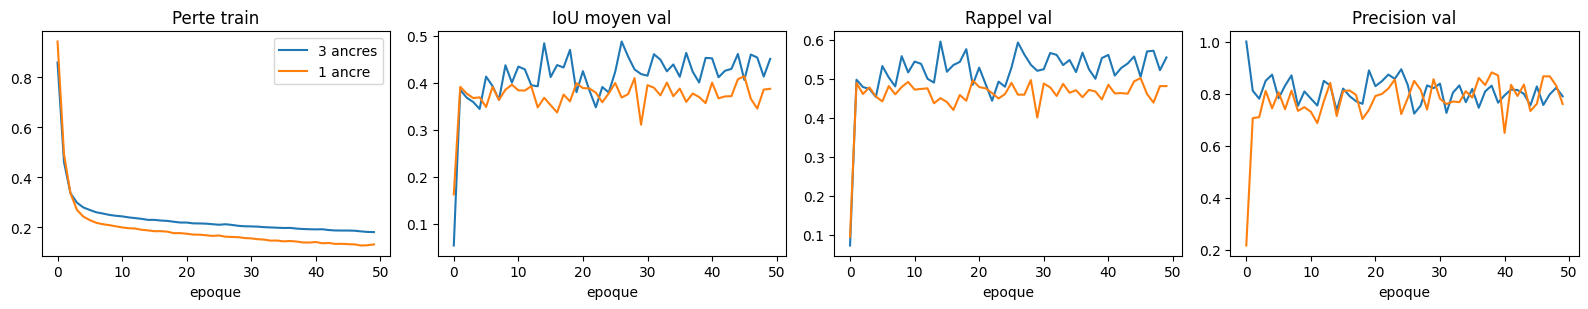

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for axis, key, title in zip(
    axes,
    ("loss", "mean_iou", "recall", "precision"),
    ("Perte train", "IoU moyen val", "Rappel val", "Precision val"),
):
    axis.plot(history_k3[key], label="3 ancres")
    axis.plot(history_base[key], label="1 ancre")
    axis.set_title(title)
    axis.set_xlabel("epoque")
axes[0].legend()
fig.tight_layout()
plt.show()

## 5. Feature maps

Le backbone produit une feature map `(32, 8, 8)`. Cette cellule appelle `feature_maps()` du modele, sans reconstruire le backbone dans le notebook.

Feature maps : (10, 32, 8, 8)


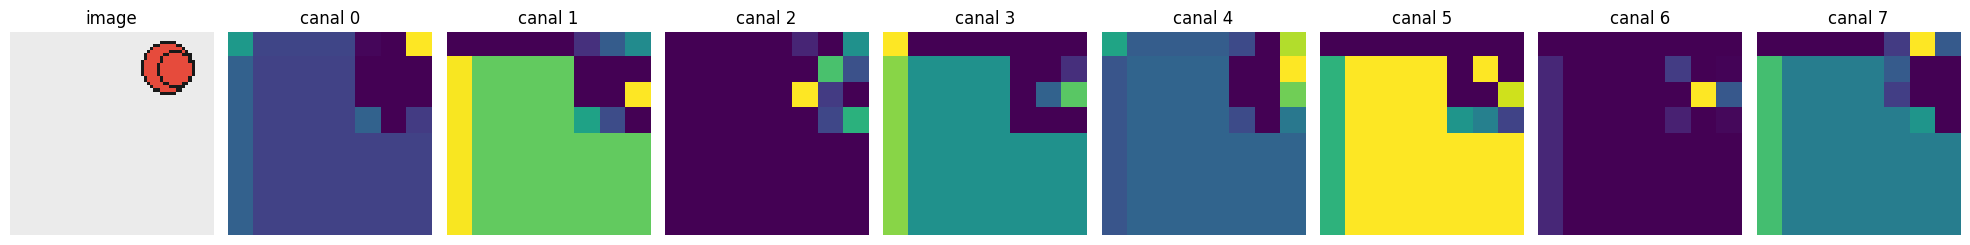

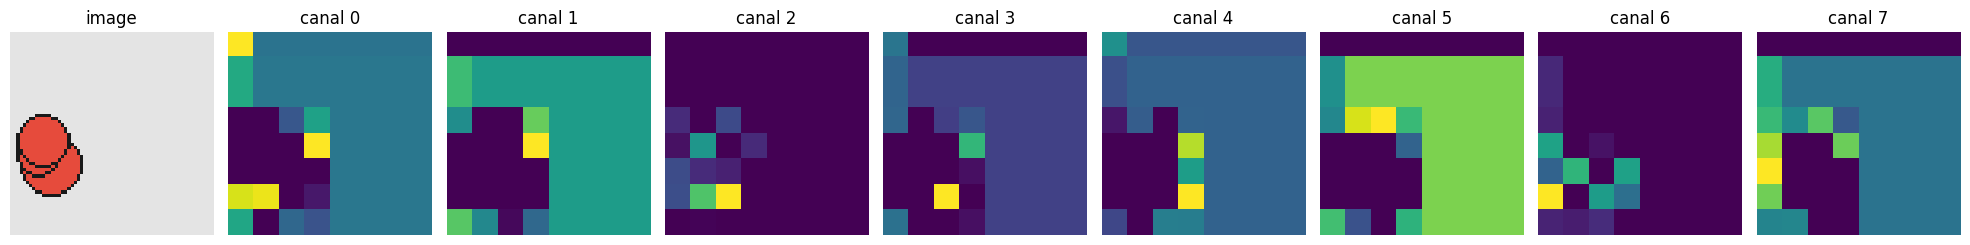

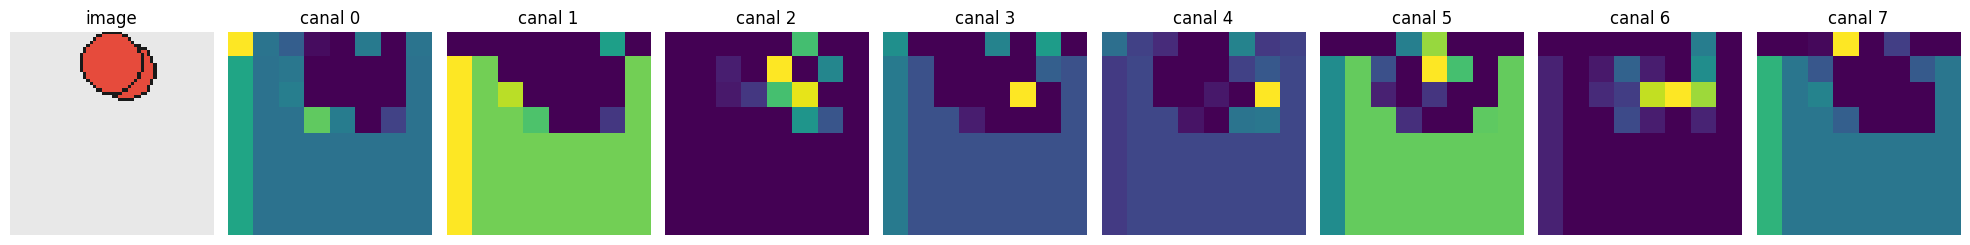

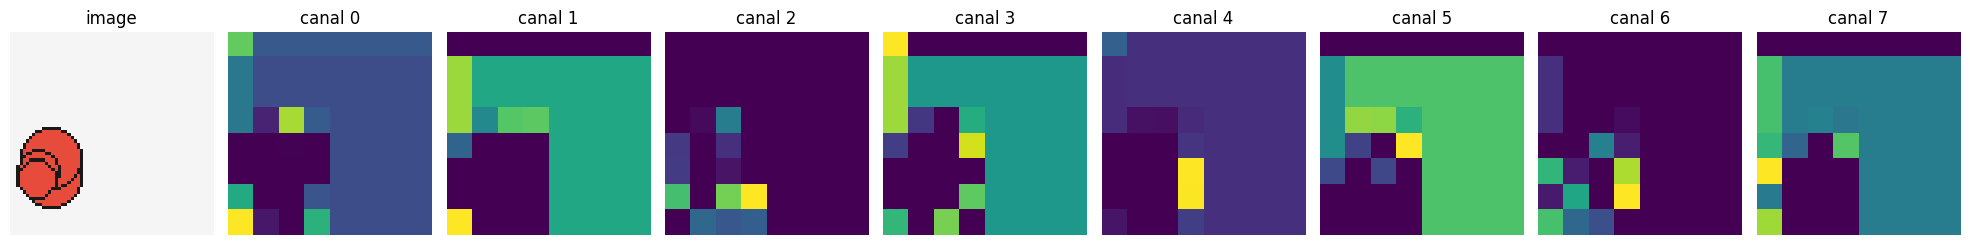

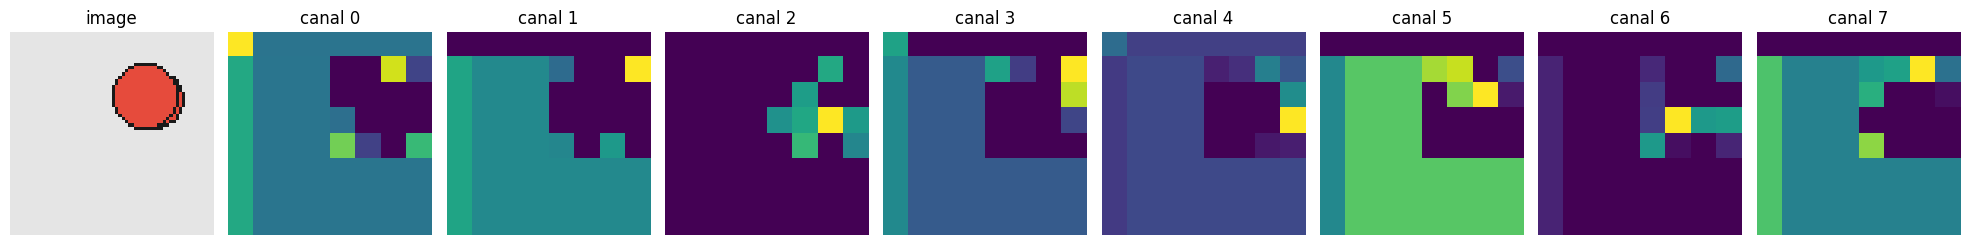

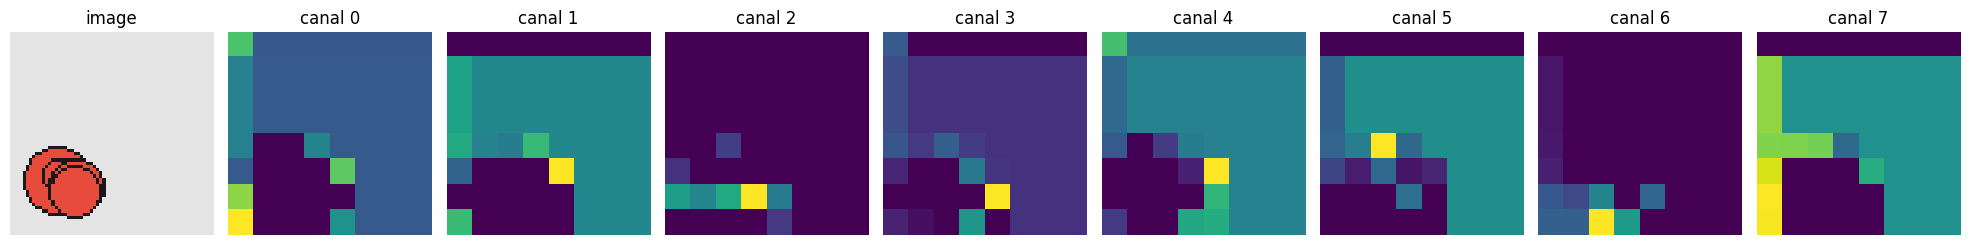

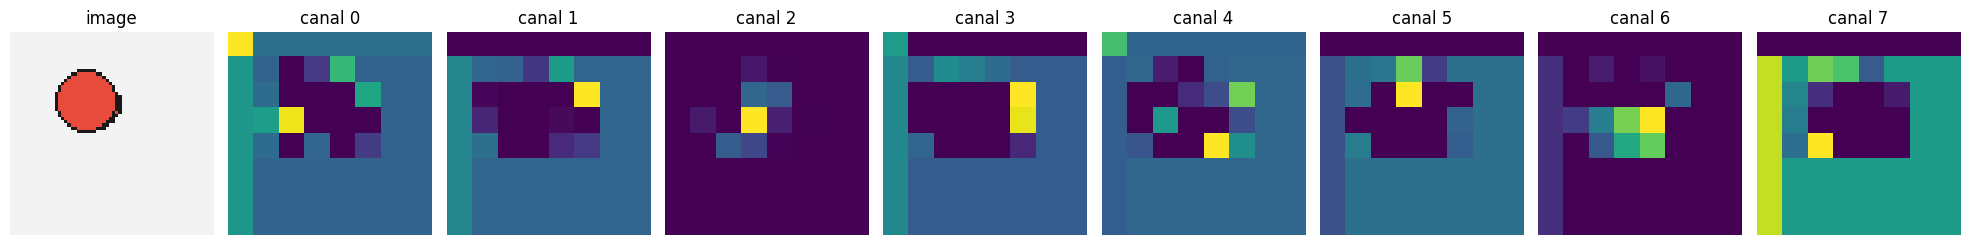

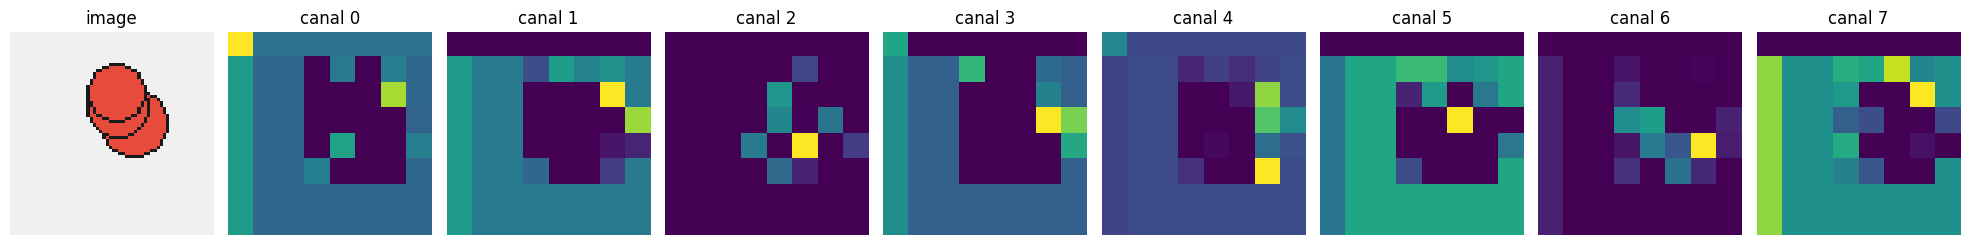

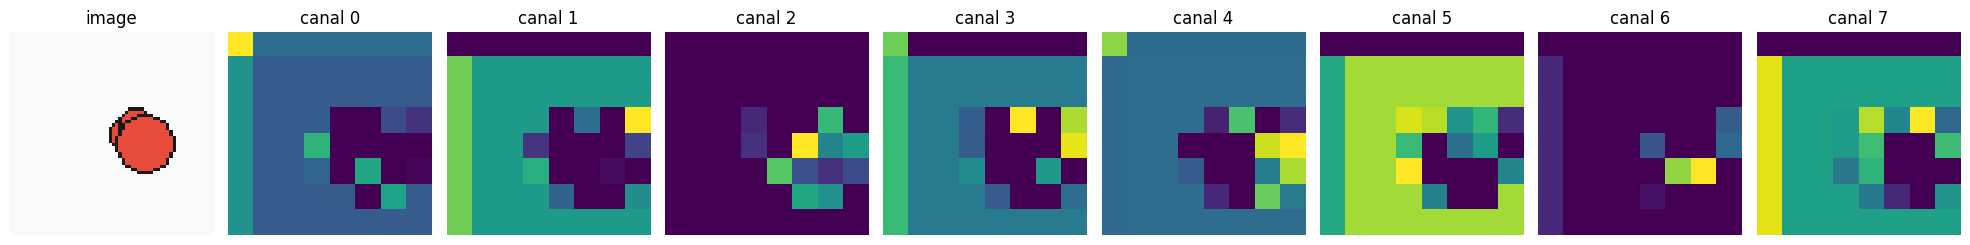

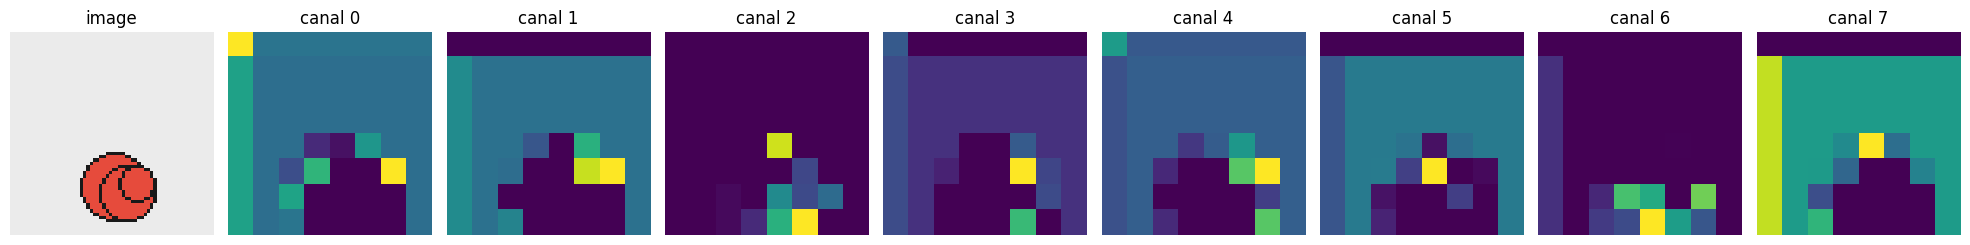

In [23]:
feature_images = torch.stack([train_dataset[i][0] for i in range(min(10, len(train_dataset)))])
with torch.no_grad():
    maps = model_k3.feature_maps(feature_images)
print("Feature maps :", tuple(maps.shape))
for index in range(len(feature_images)):
    show_feature_maps(feature_images[index], maps[index], n_maps=8)

## 6. Prediction finale : decode, seuil et NMS

`predict()` est la seule fonction appelee pour obtenir les boites finales. Elle appelle elle-meme `decode()` puis `nms()`.

Seuil de confiance : 0.7
Seuil NMS          : 0.45
image 0: 1 boite(s), scores=[0.9959321618080139]
image 1: 2 boite(s), scores=[0.9959915280342102, 0.8857734203338623]
image 2: 3 boite(s), scores=[0.9537760019302368, 0.8635953068733215, 0.7040101885795593]
image 3: 3 boite(s), scores=[0.9951287508010864, 0.978741466999054, 0.7746643424034119]
image 4: 2 boite(s), scores=[0.9936211705207825, 0.7937278747558594]
image 5: 2 boite(s), scores=[0.9864089488983154, 0.7634156346321106]
image 6: 1 boite(s), scores=[0.9484171271324158]
image 7: 4 boite(s), scores=[0.9939361214637756, 0.8297787308692932, 0.8285840153694153, 0.7653923034667969]
image 8: 2 boite(s), scores=[0.9535775184631348, 0.7865047454833984]
image 9: 2 boite(s), scores=[0.9693174362182617, 0.8711752891540527]


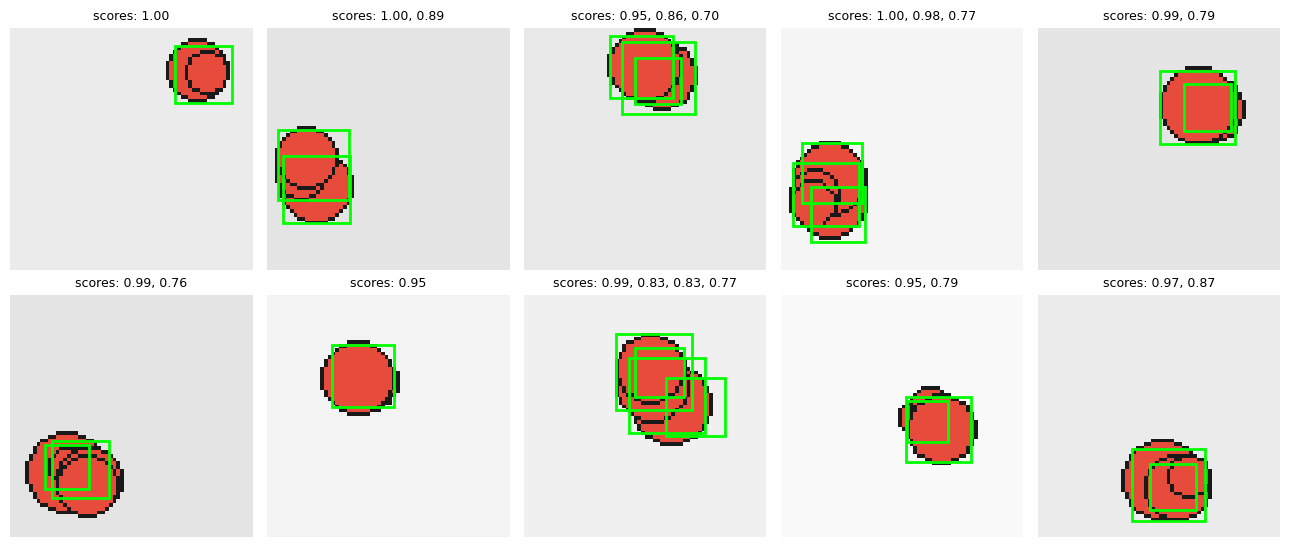

In [24]:
with torch.no_grad():
    logits = model_k3(feature_images)

results = [
    predict(
        logit,
        MODEL_SIZE,
        model_k3.anchors,
        score_threshold=SCORE_THRESHOLD,
        iou_threshold=NMS_IOU_THRESHOLD,
    )
    for logit in logits
]
print("Seuil de confiance :", SCORE_THRESHOLD)
print("Seuil NMS          :", NMS_IOU_THRESHOLD)
for index, (boxes, scores) in enumerate(results):
    print(f"image {index}: {len(boxes)} boite(s), scores={scores.tolist()}")
show_detections(
    list(feature_images),
    [boxes for boxes, _ in results],
    [scores for _, scores in results],
)

Apres decode : 192 boites candidates brutes
Apres seuil  : 3 boites candidates
Apres NMS    : 1 boites finales


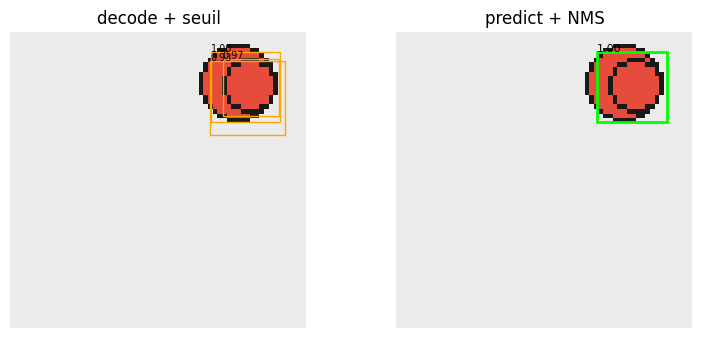

In [20]:
n_display = min(10, len(feature_images))
fig, axes = plt.subplots(n_display, 2, figsize=(8, 3.5 * n_display), squeeze=False)
for image_index in range(n_display):
    with torch.no_grad():
        decoded_boxes, decoded_scores = decode(logits[image_index], MODEL_SIZE, model_k3.anchors)
    candidate_mask = decoded_scores > SCORE_THRESHOLD
    final_boxes, final_scores = predict(
        logits[image_index], MODEL_SIZE, model_k3.anchors,
        score_threshold=SCORE_THRESHOLD, iou_threshold=NMS_IOU_THRESHOLD,
    )
    print(f"image {image_index}: decode={len(decoded_boxes)}, seuil={int(candidate_mask.sum())}, NMS={len(final_boxes)}")
    for axis in axes[image_index]:
        axis.imshow(feature_images[image_index].permute(1, 2, 0))
        axis.set_xlim(0, MODEL_SIZE)
        axis.set_ylim(MODEL_SIZE, 0)
        axis.axis("off")
    for box, score in zip(decoded_boxes[candidate_mask][:20], decoded_scores[candidate_mask][:20]):
        x1, y1, x2, y2 = box.tolist()
        axes[image_index, 0].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="orange"))
        axes[image_index, 0].text(x1, y1, f"{float(score):.2f}", fontsize=7)
    for box, score in zip(final_boxes, final_scores):
        x1, y1, x2, y2 = box.tolist()
        axes[image_index, 1].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", linewidth=2))
        axes[image_index, 1].text(x1, y1, f"{float(score):.2f}", fontsize=8)
    axes[image_index, 0].set_title(f"image {image_index}: decode + seuil")
    axes[image_index, 1].set_title(f"image {image_index}: predict + NMS")
fig.tight_layout()
plt.show()